# CatBoost đối chiếu LightGBM tại cutoff 50% và 75%

**Câu hỏi:** giữ nguyên dữ liệu, cách chia sinh viên và ngân sách HCO/VNLS,
thay LightGBM bằng CatBoost có cải thiện dự báo nguy cơ không?

Model app vẫn là **HCO–VNLS + LightGBM tại cutoff 75%**. Đây là đối chứng,
không ghi đè model đó. Code học, chọn biến, đo chỉ số và vẽ hình nằm trong các cell.
Đọc: giao thức → kiểm tra dữ liệu → bộ học → tìm biến → kết quả → nhận xét.

**Full features** là đủ 38 biến tại cutoff tương ứng, không phải dữ liệu toàn kỳ 100%.
Chỉ đánh giá validation; không fit, dự đoán hoặc dò tham số trên test.
Giảm số biến không mặc định tăng Accuracy hoặc giảm thời gian.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, json, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from lightgbm import LGBMClassifier

ROOT = next((directory for directory in [Path.cwd(), *Path.cwd().parents]
             if (directory / 'research_code').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open Jupyter from experiments/hco_vnls or its notebooks directory.")
sys.path.insert(0, str(ROOT))
from shared_code.thuc_nghiem import nap_du_lieu, chon_dac_trung, KET_QUA, HINH
from research_code.models import ModelConfig, make_pipeline
from research_code.evaluation import metric_table
from research_code.optimizers import run_search_budgeted, fitness

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
VERSIONS = {package: importlib.metadata.version(package)
            for package in ('numpy', 'pandas', 'scikit-learn', 'lightgbm', 'catboost', 'xgboost')}
print('Python:', platform.python_version())
display(pd.DataFrame(VERSIONS.items(), columns=['Thư viện', 'Phiên bản']))

Python: 3.12.6


,Thư viện,Phiên bản
0,numpy,2.2.6
1,pandas,2.2.2
2,scikit-learn,1.6.0
3,lightgbm,4.7.0
4,catboost,1.2.10
5,xgboost,3.1.2


## 1. Giao thức cố định

Cutoff 50%/75% là thời điểm quan sát trên độ dài học phần, **không lấy 50%/75% số dòng**.
Giữ cột split đã chia theo sinh viên ở seed 41: khoảng 70%/15%/15% số sinh viên.
Tỷ lệ lượt học có thể khác vì mỗi sinh viên có nhiều lượt đăng ký.

HCO, VNLS và HCO–VNLS chỉ xem **train**, dùng GroupKFold 3 phần.
Mỗi phương pháp có tối đa 8 mask mới; cache không tiêu thêm ngân sách.

$$F(m)=0.85\,\overline{AP}_{train\text{-}CV}(m)+0.15\left(1-\frac{|m|}{38}\right)$$

m là mask bật/tắt 38 biến; |m| là số biến bật. Chọn theo fitness, không theo Accuracy validation.
Ngưỡng phân loại cố định 0,5; không tối ưu ngưỡng. VNLS hiện tại chủ yếu lật một bit,
không gọi đây là triển khai đầy đủ mọi lân cận trong lý thuyết.

LightGBM được fit lại trên train với mask cũ đã chốt, không tìm mask lại.
Không trộn thời gian tìm mask cũ với phép đo mới. Cùng 80 cây không đồng nghĩa
cùng độ phức tạp, công bằng tuyệt đối hoặc đã tối ưu tham số từng bộ học.

In [2]:
MODEL_NAME = 'CatBoost'
SLUG = 'catboost'
SEED, BUDGET, POPULATION, ALPHA, THRESHOLD = 41, 8, 3, 0.85, 0.5
METHODS = ['Full features', 'HCO', 'VNLS', 'HCO-VNLS']
LIGHTGBM_PARAMS = dict(n_estimators=80, learning_rate=.055, num_leaves=15,
                      min_child_samples=35, verbosity=-1, random_state=SEED, n_jobs=4)
RESULT_PATH = KET_QUA / f'so_sanh_{SLUG}_lightgbm_50_75.csv'
TRACE_PATH = KET_QUA / f'tim_mask_{SLUG}_50_75.csv'
META_PATH = KET_QUA / f'giao_thuc_{SLUG}_50_75.json'
FROZEN_PATH = KET_QUA / 'hco_vnls_lightgbm_validation.csv'
frozen = pd.read_csv(FROZEN_PATH)
print('Seed:', SEED, '| mask mỗi phương pháp:', BUDGET, '| ngưỡng:', THRESHOLD)

Seed: 41 | mask mỗi phương pháp: 8 | ngưỡng: 0.5


## 2. Kiểm tra dữ liệu và rò rỉ

Nạp hai CSV cutoff từ quy trình hiện tại; SHA-256 ghi dấu vết dữ liệu.
Chỉ hiển thị thống kê tổng hợp, không đưa mã sinh viên vào output.
Chín cột định danh/nhãn/cấu hình không đi vào bộ chọn biến.
Kiểm tra nhóm sinh viên không giao nhau và cùng phép chia ở hai cutoff.
Chỉ train/validation được đưa vào thí nghiệm; test chỉ đếm số dòng, không đánh giá.
Không fit bộ điền thiếu trên toàn bảng trước khi chia train.

In [3]:
datasets, audit_rows, data_hashes, student_assignments = {}, [], {}, {}
excluded_by_cutoff = {}
for cutoff in (.50, .75):
    frame = nap_du_lieu(cutoff)
    columns = chon_dac_trung(frame)
    assert len(columns) == 38
    assert not frame.duplicated(['id_student', 'code_module', 'code_presentation']).any()
    assert set(frame.split) == {'train', 'validation', 'test'}
    assert frame.groupby('id_student').split.nunique().max() == 1
    for student, split in frame[['id_student', 'split']].drop_duplicates().itertuples(index=False):
        assert student not in student_assignments or student_assignments[student] == split
        student_assignments[student] = split
    train = frame.loc[frame.split.eq('train')].copy()
    valid = frame.loc[frame.split.eq('validation')].copy()
    assert not set(train.id_student).intersection(valid.id_student)
    assert set(train.risk) == {0, 1} and set(valid.risk) == {0, 1}
    datasets[cutoff] = (train, valid, columns)
    excluded_by_cutoff[str(cutoff)] = [column for column in frame if column not in columns]
    source = KET_QUA / f'du_lieu_cutoff_{round(cutoff * 100):02d}.csv'
    data_hashes[str(cutoff)] = hashlib.sha256(source.read_bytes()).hexdigest()
    audit_rows.append(dict(cutoff=cutoff, rows=len(frame), raw_columns=frame.shape[1],
                           train_rows=len(train), validation_rows=len(valid),
                           test_rows=int(frame.split.eq('test').sum()), features=len(columns),
                           train_students=train.id_student.nunique(),
                           validation_students=valid.id_student.nunique(),
                           risk_rate_train=train.risk.mean(), risk_rate_validation=valid.risk.mean()))
audit = pd.DataFrame(audit_rows)
display(audit)
print('Cột loại khỏi đầu vào:', excluded_by_cutoff['0.75'])

,cutoff,rows,raw_columns,train_rows,validation_rows,test_rows,features,train_students,validation_students,risk_rate_train,risk_rate_validation
0,0.50,24599,47,17310,3638,3651,38,15943,3380,0.372501,0.382078
1,0.75,23159,47,16297,3415,3447,38,15206,3207,0.333497,0.341728


Cột loại khỏi đầu vào: ['id_student', 'final_result', 'module_presentation_length', 'progress_fraction', 'risk', 'cutoff', 'cutoff_mode', 'score_policy', 'split']


## 3. CatBoost và tiền xử lý

Cấu hình nhỏ: 80 cây, depth 5, learning rate 0,055, L2 bằng 5 như thí nghiệm trước.
Cột chữ giữ category gốc; giá trị thiếu dùng nhãn THIEU. Biến số thiếu để NaN
cho CatBoost xử lý. Không One-Hot trước CatBoost, không học thông tin validation.

LightGBM vẫn dùng median số, mode chữ + One-Hot fit trên train.
Đây là so sánh **hai pipeline** có tiền xử lý khác nhau,
không quy mọi chênh lệch riêng cho thuật toán cây.

In [4]:
from catboost import CatBoostClassifier
MODEL_PARAMS = dict(iterations=80, depth=5, learning_rate=.055, l2_leaf_reg=5,
                    loss_function='Logloss', verbose=False, thread_count=4,
                    random_seed=SEED, allow_writing_files=False, task_type='CPU')

def prepare_categories(frame, category_columns):
    clean = frame.copy()
    for column in category_columns:
        clean[column] = clean[column].fillna('THIEU').astype(str)
    return clean

def measure_model(model_name, train_x, train_y, valid_x):
    started = time.perf_counter()
    if model_name == 'CatBoost':
        category_columns = train_x.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
        model = CatBoostClassifier(**MODEL_PARAMS)
        model.fit(prepare_categories(train_x, category_columns), train_y, cat_features=category_columns)
    else:
        model = make_pipeline(train_x, ModelConfig('LightGBM', LGBMClassifier(**LIGHTGBM_PARAMS)))
        model.fit(train_x, train_y)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    predict_x = prepare_categories(valid_x, category_columns) if model_name == 'CatBoost' else valid_x
    probability = model.predict_proba(predict_x)[:, 1]
    predict_seconds = time.perf_counter() - started
    encoded = (train_x.shape[1] if model_name == 'CatBoost'
               else len(model.named_steps['preprocess'].get_feature_names_out()))
    return probability, fit_seconds, predict_seconds, encoded

print('Cấu hình CatBoost:', MODEL_PARAMS)

Cấu hình CatBoost: {'iterations': 80, 'depth': 5, 'learning_rate': 0.055, 'l2_leaf_reg': 5, 'loss_function': 'Logloss', 'verbose': False, 'thread_count': 4, 'random_seed': 41, 'allow_writing_files': False, 'task_type': 'CPU'}


## 4. Một mask được chấm như thế nào?

Chọn các cột bật → chia train thành 3 fold theo sinh viên → fit 3 lần → lấy trung bình AP.
Thay AP vào fitness, có phần thưởng giảm biến. Cache tránh fit lại mask trùng.
std_ap_cv là độ phân tán AP **giữa ba fold của một mask** (ddof=0), không phải qua nhiều seed
và không phải khoảng tin cậy. Mỗi điểm hội tụ là một mask mới đã chấm, không phải epoch.

In [5]:
class ComparisonMaskObjective:
    def __init__(self, frame, labels, groups):
        self.frame = frame
        self.labels, self.groups = np.asarray(labels), np.asarray(groups)
        self.cache, self.fold_stats, self.records = {}, {}, []
        self.calls, self.cache_hits = 0, 0

    def __call__(self, mask):
        key = tuple(np.asarray(mask, dtype=np.int8))
        if key in self.cache:
            self.cache_hits += 1
            return self.cache[key]
        if self.calls >= BUDGET:
            raise RuntimeError('Vượt ngân sách mask mới; cần kiểm tra tìm kiếm.')
        selected = self.frame.columns[np.flatnonzero(mask)].tolist()
        if not selected:
            return 0.0, 0.0
        fold_ap = []
        for fold_train, fold_valid in GroupKFold(n_splits=3).split(self.frame, self.labels, self.groups):
            assert not set(self.groups[fold_train]).intersection(self.groups[fold_valid])
            probability, _, _, _ = measure_model(MODEL_NAME, self.frame.iloc[fold_train][selected],
                                                 self.labels[fold_train], self.frame.iloc[fold_valid][selected])
            fold_ap.append(float(average_precision_score(self.labels[fold_valid], probability)))
        mean_ap = float(np.mean(fold_ap))
        value = fitness(mean_ap, len(selected), self.frame.shape[1], ALPHA)
        self.cache[key], self.fold_stats[key] = (value, mean_ap), fold_ap
        self.calls += 1
        best_fitness = max([record['best_fitness'] for record in self.records] + [value])
        self.records.append(dict(evaluation=self.calls, mask=''.join(map(str, key)), features=len(selected),
                                 fitness_cv=value, mean_ap_cv=mean_ap, std_ap_cv=float(np.std(fold_ap)),
                                 best_fitness=best_fitness))
        return value, mean_ap

## 5. Chạy bốn trường hợp của mỗi bộ học

Mỗi cutoff: LightGBM với bốn mask đã chốt; bộ học mới với đủ biến/HCO/VNLS/HCO–VNLS.
Mỗi tìm kiếm có cache riêng. Model cuối mỗi mask chỉ fit train, đánh giá trên cùng validation.

fit_seconds gồm tiền xử lý + fit; predict_seconds gồm transform + dự đoán validation.
search_seconds là thời gian **tìm mask**, tách khỏi fit cuối. LightGBM không tìm lại mask nên
thời gian tìm mới là NaN, không ghi 0 như thể miễn phí. Mỗi thời gian đo một lần;
chưa đủ khẳng định tiết kiệm tài nguyên hoặc tốc độ ổn định.

In [6]:
rows, traces = [], []
for cutoff, (train, valid, columns) in datasets.items():
    print(f'Cutoff {cutoff:.0%}: train {len(train):,}, validation {len(valid):,}')
    reference = frozen.loc[np.isclose(frozen.cutoff, cutoff)]
    assert set(reference.method) == set(METHODS) and len(reference) == 4
    for method in METHODS:
        source = reference.loc[reference.method.eq(method)].iloc[0]
        selected = columns if method == 'Full features' else source.selected_columns.split('|')
        assert set(selected).issubset(columns) and len(selected) == source.features
        probability, fit_time, predict_time, encoded = measure_model('LightGBM', train[selected], train.risk, valid[selected])
        metrics = metric_table(valid.risk, probability, THRESHOLD)
        rows.append(dict(model='LightGBM', cutoff=cutoff, method=method, mask_source='frozen_lightgbm_05b',
                         features=len(selected), reduction_pct=100*(1-len(selected)/len(columns)), encoded_features=encoded,
                         fitness_cv=source.fitness_cv, mean_ap_cv=np.nan, std_ap_cv=np.nan, objective_calls=0,
                         search_seconds=np.nan, fit_seconds=fit_time, predict_seconds=predict_time,
                         historical_ap=source.average_precision_risk,
                         ap_delta_vs_historical=metrics['average_precision_risk']-source.average_precision_risk,
                         selected_columns='|'.join(selected), **metrics))
    for method in METHODS:
        search_time, mean_ap, std_ap, fit_value, calls = 0.0, np.nan, np.nan, np.nan, 0
        selected = columns
        if method != 'Full features':
            objective = ComparisonMaskObjective(train[columns], train.risk, train.id_student)
            search = run_search_budgeted(method, objective, seed=SEED, budget=BUDGET, population=POPULATION)
            selected = search['selected_columns']
            search_time, fit_value, mean_ap = search['wall_seconds'], search['fitness_cv'], search['average_precision_cv']
            calls = search['objective_calls']
            key = tuple(int(column in selected) for column in columns)
            std_ap = float(np.std(objective.fold_stats[key]))
            assert calls == BUDGET
            traces.extend(dict(cutoff=cutoff, method=method, **record) for record in objective.records)
        probability, fit_time, predict_time, encoded = measure_model(MODEL_NAME, train[selected], train.risk, valid[selected])
        metrics = metric_table(valid.risk, probability, THRESHOLD)
        rows.append(dict(model=MODEL_NAME, cutoff=cutoff, method=method,
                         mask_source='all_features' if method == 'Full features' else 'train_group_cv',
                         features=len(selected), reduction_pct=100*(1-len(selected)/len(columns)), encoded_features=encoded,
                         fitness_cv=fit_value, mean_ap_cv=mean_ap, std_ap_cv=std_ap, objective_calls=calls,
                         search_seconds=search_time, fit_seconds=fit_time, predict_seconds=predict_time,
                         historical_ap=np.nan, ap_delta_vs_historical=np.nan, selected_columns='|'.join(selected), **metrics))
        print(f'  {method:13s}: {len(selected):2d} biến; Acc {metrics["accuracy"]:.4f}; '
              f'AP {metrics["average_precision_risk"]:.4f}; search {search_time:.1f}s')
result, trajectory = pd.DataFrame(rows), pd.DataFrame(traces)
assert len(result) == 16 and not result.duplicated(['model', 'cutoff', 'method']).any()
reference_drift = float(result.loc[result.model.eq('LightGBM'), 'ap_delta_vs_historical'].abs().max())
print('Chênh AP lớn nhất khi tái lập LightGBM:', reference_drift)
display(result[['cutoff', 'model', 'method', 'features', 'accuracy', 'precision_risk', 'recall_risk',
                'f1_risk', 'weighted_f1', 'average_precision_risk', 'roc_auc', 'brier_score',
                'fit_seconds', 'predict_seconds', 'search_seconds']].round(5))

Cutoff 50%: train 17,310, validation 3,638


  Full features: 38 biến; Acc 0.8101; AP 0.8489; search 0.0s


  HCO          : 17 biến; Acc 0.8079; AP 0.8414; search 114.8s


  VNLS         : 16 biến; Acc 0.8048; AP 0.8404; search 104.9s


  HCO-VNLS     : 17 biến; Acc 0.8037; AP 0.8426; search 115.8s
Cutoff 75%: train 16,297, validation 3,415


  Full features: 38 biến; Acc 0.8714; AP 0.8979; search 0.0s


  HCO          : 17 biến; Acc 0.8679; AP 0.8885; search 106.4s


  VNLS         : 15 biến; Acc 0.8691; AP 0.8854; search 98.0s


  HCO-VNLS     : 16 biến; Acc 0.8589; AP 0.8839; search 101.8s
Chênh AP lớn nhất khi tái lập LightGBM: 0.0


,cutoff,model,method,features,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,roc_auc,brier_score,fit_seconds,predict_seconds,search_seconds
0,0.50,LightGBM,Full features,38,0.81281,0.84653,0.62302,0.71778,0.80564,0.85109,0.87301,0.13128,0.33828,0.02144,NaN
1,0.50,LightGBM,HCO,17,0.80786,0.84242,0.61151,0.70863,0.80011,0.84518,0.86477,0.13367,0.15887,0.01467,NaN
2,0.50,LightGBM,VNLS,16,0.81006,0.84707,0.61367,0.71172,0.80234,0.84698,0.86664,0.13336,0.12820,0.01244,NaN
3,0.50,LightGBM,HCO-VNLS,16,0.80539,0.84444,0.60144,0.70252,0.79698,0.84515,0.86770,0.13424,0.14145,0.01189,NaN
4,0.50,CatBoost,Full features,38,0.81006,0.85773,0.60288,0.70807,0.80148,0.84889,0.87228,0.13243,5.63896,0.03347,0.00000
5,0.50,CatBoost,HCO,17,0.80786,0.86254,0.59137,0.70166,0.79845,0.84138,0.86102,0.13652,4.28387,0.01134,114.80068
6,0.50,CatBoost,VNLS,16,0.80484,0.84836,0.59568,0.69992,0.79599,0.84044,0.86187,0.13673,4.29394,0.00887,104.91685
7,0.50,CatBoost,HCO-VNLS,17,0.80374,0.85135,0.58921,0.69643,0.79441,0.84262,0.86525,0.13577,4.34634,0.01054,115.81980
8,0.75,LightGBM,Full features,38,0.87350,0.92000,0.68980,0.78844,0.86831,0.89699,0.91789,0.09455,0.25231,0.01807,NaN
9,0.75,LightGBM,HCO,17,0.87057,0.92200,0.67866,0.78184,0.86488,0.89154,0.91214,0.09706,0.16863,0.01462,NaN


## 6. Chỉ số và danh sách biến được chọn

Accuracy: tỷ lệ đúng toàn bộ; Precision risk: tỷ lệ cảnh báo đúng;
Recall risk: phát hiện bao nhiêu ca nguy cơ thực; F1 risk: cân bằng Precision/Recall lớp nguy cơ.
Weighted F1: trung bình F1 hai lớp có trọng số. AP: chất lượng xếp hạng qua nhiều ngưỡng.
ROC AUC: xếp ca nguy cơ cao hơn ca không nguy cơ; Brier: sai số xác suất, thấp hơn tốt hơn.

Trước tiên so giảm biến với đủ 38 biến **cùng bộ học và cutoff**. 38 còn 17 là giảm 55,26%
biến gốc, không tự động giảm 55,26% thời gian/dung lượng. Tên biến giữ nguyên để đối chiếu code.

In [7]:
own = result.loc[result.model.eq(MODEL_NAME)].copy()
baselines = own.loc[own.method.eq('Full features')].set_index('cutoff')
comparison = own.loc[own.method.ne('Full features')].copy()
for metric in ('accuracy', 'average_precision_risk', 'recall_risk', 'f1_risk'):
    comparison[f'delta_{metric}'] = comparison[metric] - comparison.cutoff.map(baselines[metric])
comparison['fit_speed_ratio_full_over_selected'] = comparison.cutoff.map(baselines.fit_seconds) / comparison.fit_seconds
display(comparison[['cutoff', 'method', 'features', 'reduction_pct', 'delta_accuracy',
                    'delta_average_precision_risk', 'delta_recall_risk', 'delta_f1_risk',
                    'fit_speed_ratio_full_over_selected']].round(5))
display(own.loc[own.method.ne('Full features'), ['cutoff', 'method', 'features', 'selected_columns']]
        .style.set_properties(subset=['selected_columns'], **{'white-space': 'normal', 'max-width': '800px'}))

,cutoff,method,features,reduction_pct,delta_accuracy,delta_average_precision_risk,delta_recall_risk,delta_f1_risk,fit_speed_ratio_full_over_selected
5,0.50,HCO,17,55.26316,-0.00220,-0.00751,-0.01151,-0.00640,1.31632
6,0.50,VNLS,16,57.89474,-0.00522,-0.00844,-0.00719,-0.00815,1.31324
7,0.50,HCO-VNLS,17,55.26316,-0.00632,-0.00627,-0.01367,-0.01164,1.29740
13,0.75,HCO,17,55.26316,-0.00351,-0.00932,-0.00771,-0.00655,1.22939
14,0.75,VNLS,15,60.52632,-0.00234,-0.01246,-0.00428,-0.00414,1.18836
15,0.75,HCO-VNLS,16,57.89474,-0.01259,-0.01396,-0.03770,-0.02645,0.69772


,cutoff,method,features,selected_columns
5,0.500000,HCO,17,code_module|gender|region|highest_education|studied_credits|disability|total_clicks_to_t|clicks_forumng_to_t|clicks_resource_to_t|assessments_due_to_t|active_day_ratio|clicks_per_active_day|submission_rate|missing_rate|days_since_last_activity|clicks_recent_7|clicks_first_half
6,0.500000,VNLS,16,code_module|code_presentation|region|num_of_prev_attempts|studied_credits|disability|cutoff_day|total_clicks_to_t|clicks_homepage_to_t|clicks_oucontent_to_t|last_activity_day|clicks_per_active_day|missing_rate|late_rate|days_since_last_activity|clicks_second_half
7,0.500000,HCO-VNLS,17,code_module|gender|highest_education|age_band|studied_credits|date_registration|total_clicks_to_t|clicks_resource_to_t|clicks_url_to_t|active_days_to_t|assessments_submitted_to_t|late_submissions_to_t|missing_submissions_to_t|active_day_ratio|days_since_last_activity|clicks_recent_7|clicks_recent_30
13,0.750000,HCO,17,code_module|gender|region|highest_education|studied_credits|disability|total_clicks_to_t|clicks_forumng_to_t|clicks_resource_to_t|assessments_due_to_t|active_day_ratio|clicks_per_active_day|submission_rate|missing_rate|days_since_last_activity|clicks_recent_7|clicks_first_half
14,0.750000,VNLS,15,code_module|code_presentation|region|num_of_prev_attempts|studied_credits|disability|cutoff_day|total_clicks_to_t|clicks_homepage_to_t|clicks_oucontent_to_t|last_activity_day|clicks_per_active_day|missing_rate|days_since_last_activity|clicks_second_half
15,0.750000,HCO-VNLS,16,code_module|gender|highest_education|age_band|studied_credits|date_registration|total_clicks_to_t|clicks_resource_to_t|clicks_url_to_t|active_days_to_t|assessments_submitted_to_t|late_submissions_to_t|active_day_ratio|days_since_last_activity|clicks_recent_7|clicks_recent_30


## 7. Vẽ hình và lưu bằng chứng

Hình đầu gồm AP/Recall, Accuracy/F1 và thời gian fit/dự đoán, mỗi cột một cutoff.
Đường nối giúp đọc bốn trường hợp, **không biểu diễn quá trình học**.
Hình thứ hai là fitness tốt nhất train-CV theo số mask mới, không phải Accuracy validation.
Hình lưu ở figures, bảng ở results. Không xuất xác suất cá nhân hoặc model đối chứng.

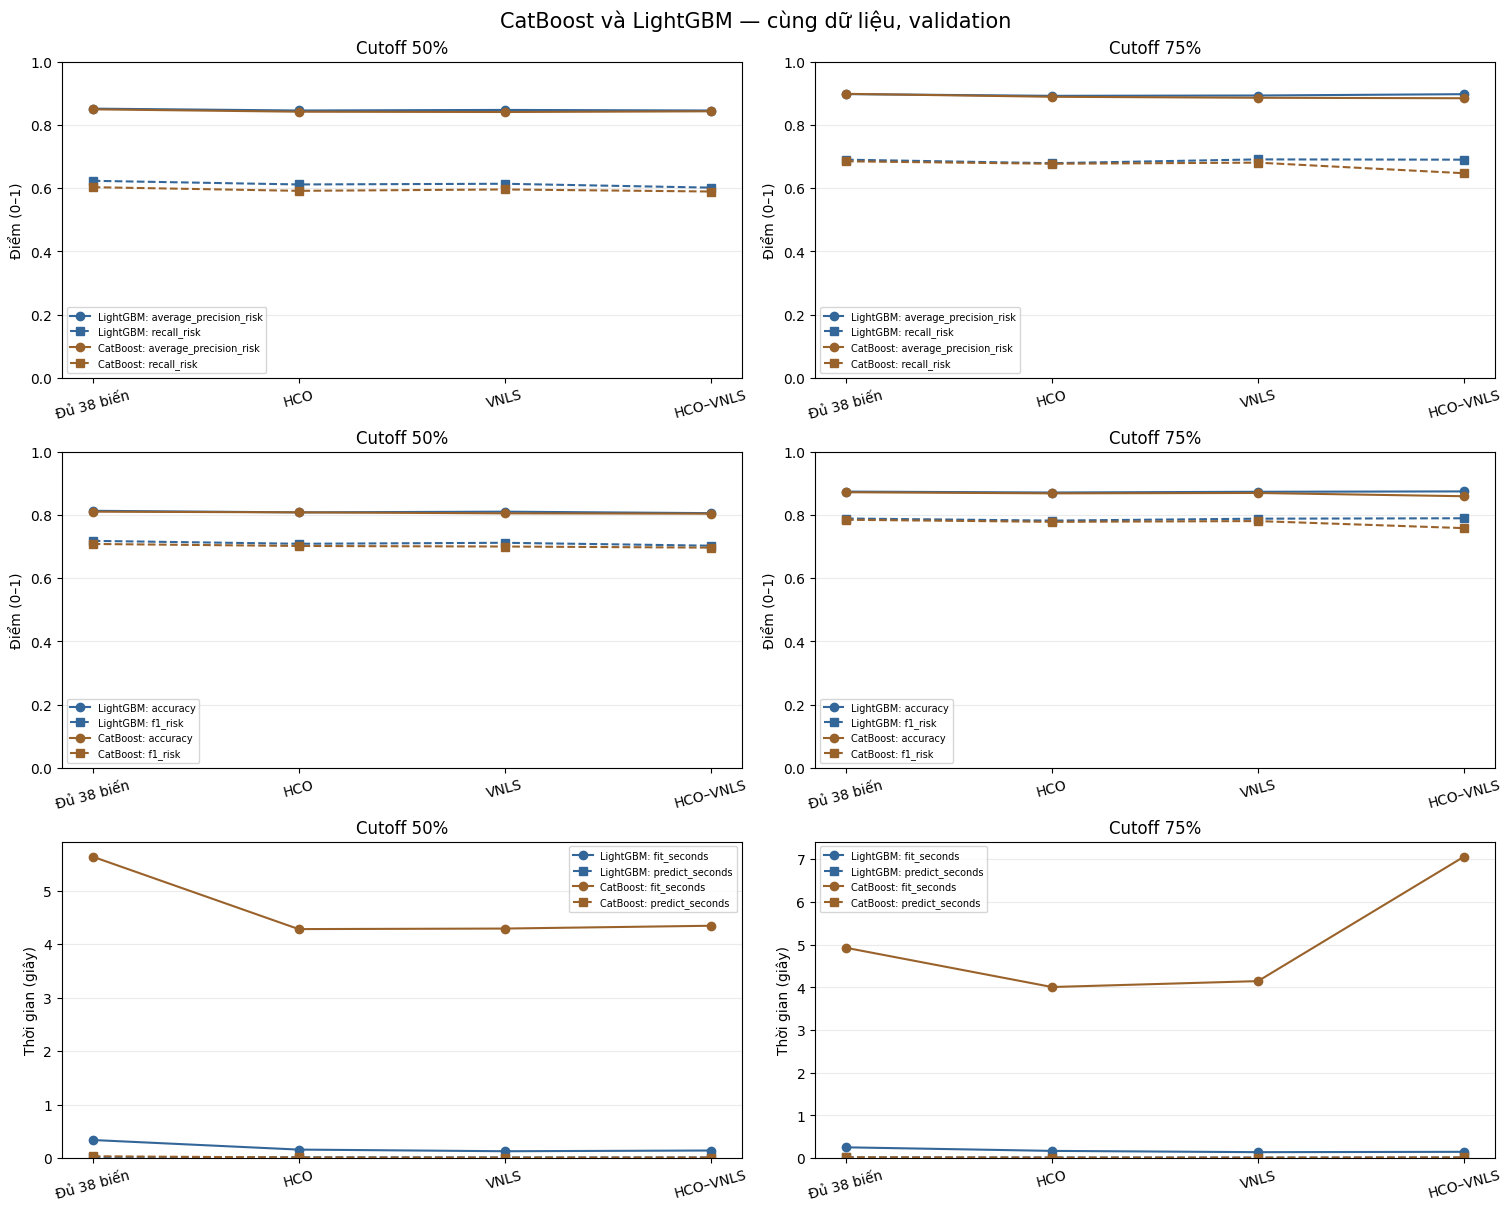

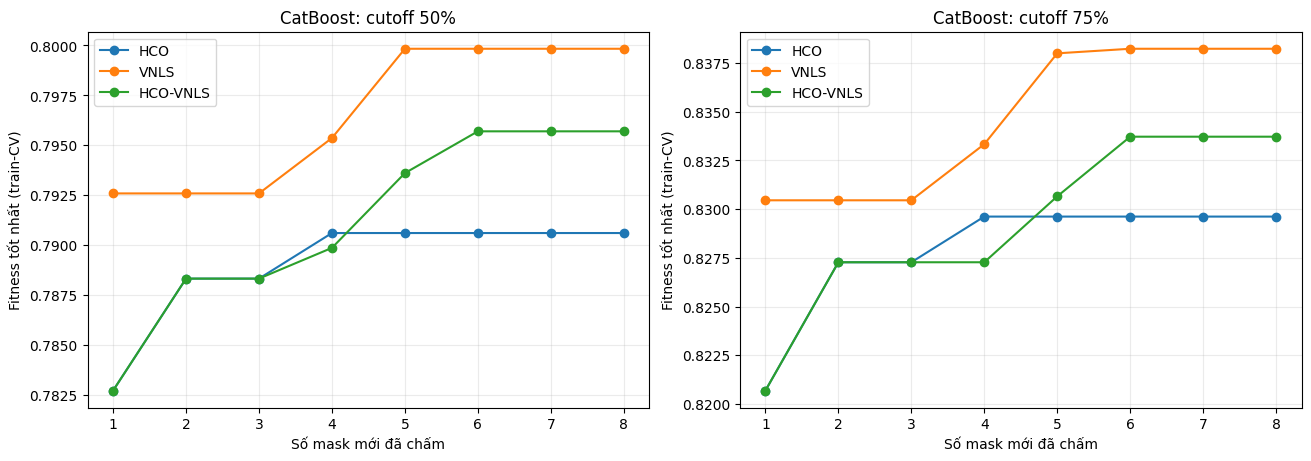

Đã lưu bảng, hình, giao thức; không thay model app.


In [8]:
figure, axes = plt.subplots(3, 2, figsize=(15, 12), constrained_layout=True)
colors = {'LightGBM': '#336699', MODEL_NAME: '#9a622b'}
for column_index, cutoff in enumerate((.50, .75)):
    subset = result.loc[np.isclose(result.cutoff, cutoff)]
    for name in ('LightGBM', MODEL_NAME):
        ordered = subset.loc[subset.model.eq(name)].set_index('method').loc[METHODS]
        for row_index, metrics in enumerate([('average_precision_risk', 'recall_risk'),
                                             ('accuracy', 'f1_risk'), ('fit_seconds', 'predict_seconds')]):
            for metric, marker in zip(metrics, ['o-', 's--']):
                axes[row_index, column_index].plot(np.arange(4), ordered[metric], marker,
                                                   color=colors[name], label=f'{name}: {metric}')
    for row_index in range(3):
        axis = axes[row_index, column_index]
        axis.set_xticks(np.arange(4), ['Đủ 38 biến', 'HCO', 'VNLS', 'HCO–VNLS'], rotation=15)
        axis.set_title(f'Cutoff {cutoff:.0%}')
        axis.set_ylabel('Điểm (0–1)' if row_index < 2 else 'Thời gian (giây)')
        axis.grid(axis='y', alpha=.25)
        axis.legend(fontsize=7, ncol=1)
        axis.set_ylim(0, 1) if row_index < 2 else axis.set_ylim(bottom=0)
figure.suptitle(f'{MODEL_NAME} và LightGBM — cùng dữ liệu, validation', fontsize=15)
metric_figure = HINH / f'so_sanh_{SLUG}_lightgbm_50_75.png'
figure.savefig(metric_figure, dpi=180)
plt.show()
plt.close(figure)
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for axis, cutoff in zip(axes, (.50, .75)):
    for method in METHODS[1:]:
        trace = trajectory.loc[np.isclose(trajectory.cutoff, cutoff) & trajectory.method.eq(method)]
        axis.plot(trace.evaluation, trace.best_fitness, 'o-', label=method)
    axis.set(title=f'{MODEL_NAME}: cutoff {cutoff:.0%}', xlabel='Số mask mới đã chấm', ylabel='Fitness tốt nhất (train-CV)')
    axis.set_xticks(range(1, BUDGET + 1))
    axis.grid(alpha=.25)
    axis.legend()
trace_figure = HINH / f'tim_mask_{SLUG}_50_75.png'
figure.savefig(trace_figure, dpi=180)
plt.show()
plt.close(figure)
result.to_csv(RESULT_PATH, index=False, encoding='utf-8-sig')
trajectory.to_csv(TRACE_PATH, index=False, encoding='utf-8-sig')
metadata = dict(model=MODEL_NAME, run_time_local=time.strftime('%Y-%m-%dT%H:%M:%S'),
                python=platform.python_version(), versions=VERSIONS, params=MODEL_PARAMS,
                lightgbm_params=LIGHTGBM_PARAMS, seed=SEED, budget=BUDGET, population=POPULATION,
                alpha=ALPHA, threshold=THRESHOLD, cv='GroupKFold(n_splits=3) inside train',
                split_source='Existing student split column, seed 41', test_evaluated=False,
                production_model_changed=False, data_sha256=data_hashes, excluded_columns=excluded_by_cutoff,
                data_audit=audit.to_dict(orient='records'), lightgbm_max_ap_drift=reference_drift,
                frozen_csv_sha256=hashlib.sha256(FROZEN_PATH.read_bytes()).hexdigest(),
                timing_repeats=1, reference_search_rerun=False,
                missing_policy=('CatBoost numeric NaN; categorical THIEU' if MODEL_NAME == 'CatBoost'
                                else 'train-only median/mode + OneHot'),
                artifacts=[RESULT_PATH.name, TRACE_PATH.name, metric_figure.name, trace_figure.name])
META_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu bảng, hình, giao thức; không thay model app.')

## 8. Nhận xét từ số liệu vừa chạy

Cell lấy số liệu trực tiếp, không viết sẵn rằng bộ học mới thắng.
Đọc mức giảm biến cùng thay đổi AP/Recall/F1. Chênh nhỏ chưa có ý nghĩa thống kê;
một seed và ngân sách 8 chỉ là pilot.

In [9]:
paragraphs = []
for cutoff in (.50, .75):
    subset = result.loc[np.isclose(result.cutoff, cutoff)]
    full = subset.loc[subset.model.eq(MODEL_NAME) & subset.method.eq('Full features')].iloc[0]
    hybrid = subset.loc[subset.model.eq(MODEL_NAME) & subset.method.eq('HCO-VNLS')].iloc[0]
    reference = subset.loc[subset.model.eq('LightGBM') & subset.method.eq('HCO-VNLS')].iloc[0]
    paragraphs.append(
        f'### Cutoff {cutoff:.0%}\n'
        f'{MODEL_NAME} đủ 38 biến: Accuracy **{full.accuracy:.2%}**, AP **{full.average_precision_risk:.4f}**. '
        f'Hybrid {MODEL_NAME}: **{hybrid.features} biến**, giảm **{hybrid.reduction_pct:.2f}%**, '
        f'Accuracy **{hybrid.accuracy:.2%}**, Precision **{hybrid.precision_risk:.2%}**, '
        f'Recall **{hybrid.recall_risk:.2%}**, F1 risk **{hybrid.f1_risk:.2%}**, AP **{hybrid.average_precision_risk:.4f}**.\n\n'
        f'So hybrid LightGBM: chênh Accuracy **{100*(hybrid.accuracy-reference.accuracy):+.2f} điểm %**, '
        f'AP **{hybrid.average_precision_risk-reference.average_precision_risk:+.4f}**. '
        f'So {MODEL_NAME} đủ biến: AP **{hybrid.average_precision_risk-full.average_precision_risk:+.4f}**, '
        f'Recall **{100*(hybrid.recall_risk-full.recall_risk):+.2f} điểm %**. '
        f'Search **{hybrid.search_seconds:.2f}s**, fit **{hybrid.fit_seconds:.3f}s**, '
        f'dự đoán validation **{hybrid.predict_seconds:.3f}s**.\n')
display(Markdown('\n'.join(paragraphs)))
print('Giữ nguyên HCO–VNLS + LightGBM 75% cho app, không tự thay model triển khai.')

### Cutoff 50%
CatBoost đủ 38 biến: Accuracy **81.01%**, AP **0.8489**. Hybrid CatBoost: **17 biến**, giảm **55.26%**, Accuracy **80.37%**, Precision **85.14%**, Recall **58.92%**, F1 risk **69.64%**, AP **0.8426**.

So hybrid LightGBM: chênh Accuracy **-0.16 điểm %**, AP **-0.0025**. So CatBoost đủ biến: AP **-0.0063**, Recall **-1.37 điểm %**. Search **115.82s**, fit **4.346s**, dự đoán validation **0.011s**.

### Cutoff 75%
CatBoost đủ 38 biến: Accuracy **87.14%**, AP **0.8979**. Hybrid CatBoost: **16 biến**, giảm **57.89%**, Accuracy **85.89%**, Precision **91.52%**, Recall **64.70%**, F1 risk **75.80%**, AP **0.8839**.

So hybrid LightGBM: chênh Accuracy **-1.52 điểm %**, AP **-0.0129**. So CatBoost đủ biến: AP **-0.0140**, Recall **-3.77 điểm %**. Search **101.82s**, fit **7.062s**, dự đoán validation **0.016s**.


Giữ nguyên HCO–VNLS + LightGBM 75% cho app, không tự thay model triển khai.


## 9. Giới hạn khi báo cáo

- Chỉ validation trên dataset hiện tại; chưa chứng minh tổng quát sang trường/học kỳ khác.
- Test từng được xem trong lịch sử; không gọi test cũ là holdout mới.
- Một seed, cấu hình cố định, 8 mask; chưa tối ưu hyperparameter hoặc chứng minh tối ưu toàn cục.
- Mỗi bộ học có mask riêng, so hybrid là so pipeline end-to-end,
  không tách riêng tác động của bộ học khỏi tập biến.
- Thời gian đo một lần, cùng máy nhưng nối tiếp; không phải benchmark ổn định.
- Chỉ đánh giá dự báo, không chứng minh gợi ý làm tăng điểm.
- Không xuất dự đoán cá nhân, không ghi đè model/notebook đã chốt, không tự push.